In [3]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("cars.csv")

rows,cols = df.shape

names = []

for i in range(rows):

    fullName = ""

    fullName = fullName + df.loc[i, "First Name"]

    fullName = fullName + " " + df.loc[i, "Last Name"]

    names.append(fullName)

df.insert(0, "Name", names)

df = df[["Name", "Country", "Car Brand", "Car Model", "Car Color", "Year of Manufacture", "Credit Card Type"]]

# Check for duplicates 
# print(df.duplicated().sum())

# Check for null values
# print(df.isnull().sum())

display(df)


,Name,Country,Car Brand,Car Model,Car Color,Year of Manufacture,Credit Card Type
0,Yetty Arghent,Indonesia,Ford,Club Wagon,Teal,1993,mastercard
1,Crystal Bosworth,China,Cadillac,Escalade ESV,Fuscia,2007,mastercard
2,Monro Houdhury,Indonesia,Mazda,Miata MX-5,Orange,2009,maestro
3,Bowie Clair,China,Audi,A4,Orange,2005,instapayment
4,Myrvyn McAllister,Czech Republic,Nissan,Maxima,Pink,1994,maestro
...,...,...,...,...,...,...,...
29995,Valida Smoote,Afghanistan,Nissan,Altima,Yellow,2010,jcb
29996,Anthea Deport,Indonesia,Kia,Rio,Red,2008,china-unionpay
29997,Albertine Danelut,Japan,Toyota,Tacoma Xtra,Pink,2004,americanexpress
29998,Alayne Golda,Kyrgyzstan,Audi,riolet,Turquoise,1996,americanexpress


## ANALYSIS 1: DISTRIBUTION OF CAR MANUFACTURING YEARS

We want to examine the distribution of car manufacturing years in the dataset. We will use Z-scores to find any potential outliers and determine how much the old/new cars affect the average manufacturing year. This will help us better understand our dataset and decide whether to remove these outliers or not

In [4]:
df['Year of Manufacture'].describe()


count    30000.000000
mean      2000.247500
std          9.131398
min       1909.000000
25%       1995.000000
50%       2002.000000
75%       2007.000000
max       2013.000000
Name: Year of Manufacture, dtype: float64

In [5]:
# Z-SCORES
# Trying to find any outliers ; Keep count of # of outliers
mean = df['Year of Manufacture'].mean()
std = df['Year of Manufacture'].std()

num = 0

for i in df.index:
    year = df.loc[i, 'Year of Manufacture']
    car_brand = df.loc[i, 'Car Brand']
    model = df.loc[i, 'Car Model']
    
    zscore = (year - mean) / std
    if abs(zscore) > 3:
        num += 1

print(f"Num of outliers: {num}")
# Percent of outliers that make up the data
percent_of_outliers = (num / len(df)) * 100
print(f"Percent of outliers that make up the data : {percent_of_outliers}")


Num of outliers: 538
Percent of outliers that make up the data : 1.7933333333333332


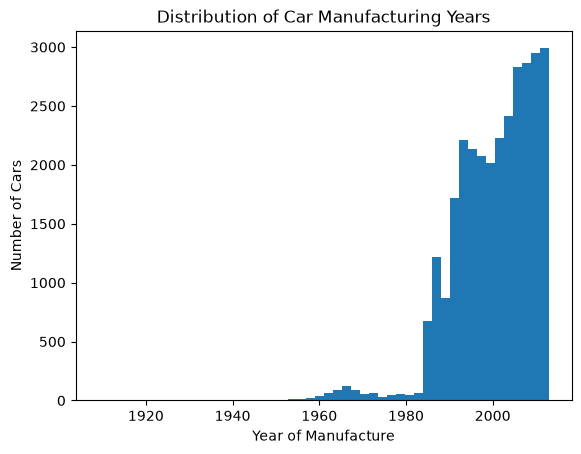

In [6]:
plt.hist(df['Year of Manufacture'], bins=50)
plt.xlabel('Year of Manufacture')
plt.ylabel('Number of Cars')
plt.title('Distribution of Car Manufacturing Years')
plt.show()

In [7]:
# Want to see what the mean would be without outliers

df_copy = df.copy()

zscore = ((df_copy['Year of Manufacture']) - mean) / std

df_copy = df_copy[abs(zscore) <= 3]

no_outliers_mean = (df_copy['Year of Manufacture'].mean())

print(f"Mean with no outliers: {no_outliers_mean}")
print(f"Mean with outliers: {mean}")

difference = no_outliers_mean - mean
print(f"Difference in means: {difference}")



Mean with no outliers: 2000.8941687597583
Mean with outliers: 2000.2475
Difference in means: 0.6466687597583132


## CONCLUSION ON DISTRIBUTION OF CAR MANUFACTURING YEARS

Most cars in the dataset were manufactured in recent years so our distrubution was left skewed.
 The mean manufacturing year was  2000.24, while the median was 2002. 
 Using Z-scores we found 538 potential outliers which made up about 1.79% of our dataset. 
 After excluding the outliers, the mean increased to 2000.89, thats only a 0.65 year difference.
This shows that the outliers have a relatively small impact on the mean. 
We decided to keep the outliers in our original dataset because older manufacturing years can still be valid

## HYPOTHESIS TEST 1: Car Model and Credit Card Type

Is there a relationship between the data's Car Model and Credit Card Type? In order to determine this, we will perform a hypothesis Test with the following hypothesis:

H0: There is an independent relationship between Car Model and Credit Card Type.
Ha: There is NOT an independent relationship between Car Model and Credit Card Type.

In order to conduct this hypothesis test, we will perform a Chi-Squared Test, as we are comparing categorical variables. We will set our alpha value at 0.05.

In [ ]:
# Code for Hypothesis Testing
from scipy.stats import chi2_contingency #import chi squared

# Create a contingency table
table = pd.crosstab(df["Car Model"], df["Credit Card Type"])

# Perform the chi-squared test
chi2, p_value, dof, expected = chi2_contingency(table)

# Set significance level
alpha = 0.05

print("Chi-squared statistic:", chi2)
print("P-value:", p_value)
print("Degrees of freedom:", dof)

if p_value <= alpha:
    print("Reject H0: There is evidence of an association.")
else:
    print("Fail to reject H0: Insufficient evidence of an association.")

Chi-squared statistic: 14663.582217706751
P-value: 0.9915174195849422
Degrees of freedom: 15075
Fail to reject H0: Insufficient evidence of an association.


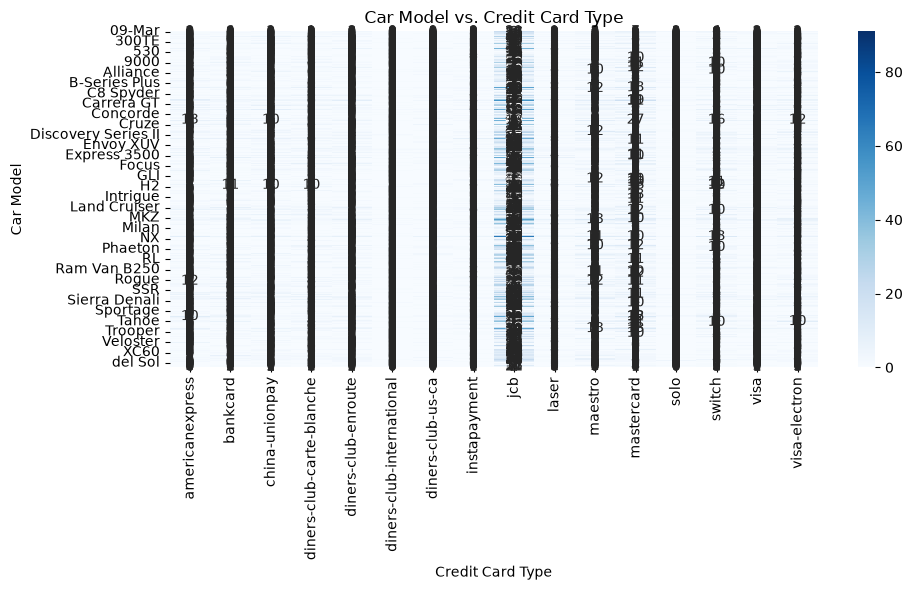

In [12]:
# Code for graphing
import seaborn as sns

# Plot heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(table, annot=True, fmt="d", cmap="Blues")

plt.title("Car Model vs. Credit Card Type")
plt.xlabel("Credit Card Type")
plt.ylabel("Car Model")
plt.tight_layout()
plt.show()

After performing our Chi Squared Test, we recieved a p-value of approximatelt 0.992. This means that, under the assumption that Car Model and Credit Card Type are independent, we had a 99.2% probability of recieving our data. This is not below our alpha value, which means that our data is not sufficient to reject the null hypothesis. Hence, we conclude that there is an independent relationship between Car Model and Credit Card Type.

The heatmap we graphed also suggest as such, as there isn't much grouping between Car Model and Credit Card Type. However, the heat map does seem to suggest that jcb is the most reported Credit Card Type. This may be a data point worth considering.